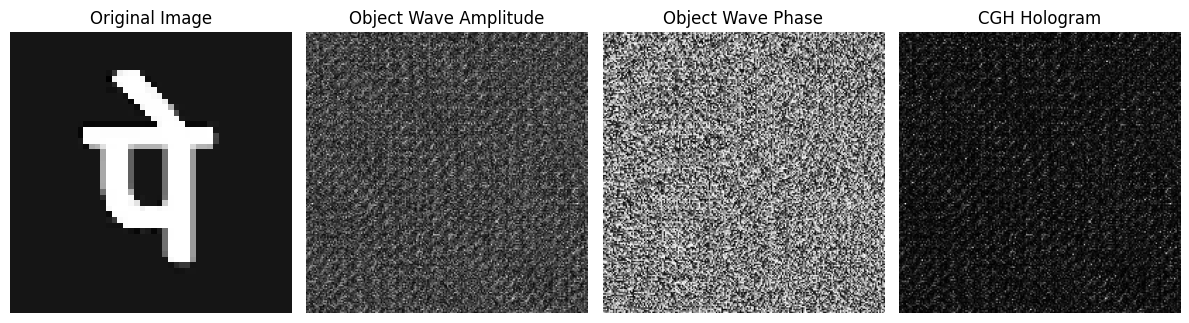

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(
    "images.jpg",
    cv2.IMREAD_GRAYSCALE
)

img = cv2.resize(img, (50, 50))

points = []

for y in range(img.shape[0]):
    for x in range(img.shape[1]):

        if img[y, x] > 100:

            X = x * 0.001
            Y = y * 0.001
            Z = -0.2

            points.append((X, Y, Z))

wavelength = 532e-9

hologram_width = 2e-3
hologram_height = 2e-3

delta = 10e-6

samples_x = int(hologram_width / delta)
samples_y = int(hologram_height / delta)

k = 2 * np.pi / wavelength

x = np.linspace(
    -hologram_width / 2,
    hologram_width / 2,
    samples_x
)

y = np.linspace(
    -hologram_height / 2,
    hologram_height / 2,
    samples_y
)

X, Y = np.meshgrid(x, y)

object_wave = np.zeros(
    (samples_y, samples_x),
    dtype=complex
)

for px, py, pz in points:

    r = np.sqrt(
        (X - px)**2 +
        (Y - py)**2 +
        (0 - pz)**2
    )

    object_wave += np.exp(1j * k * r) / r

object_amplitude = np.abs(object_wave)

object_phase = np.angle(object_wave)


reference_wave = np.ones(
    (samples_y, samples_x),
    dtype=complex
)


total_wave = object_wave + reference_wave


hologram = np.abs(total_wave)**2

object_amplitude_display = (
    object_amplitude - object_amplitude.min()
)

object_amplitude_display = (
    object_amplitude_display /
    object_amplitude_display.max() * 255
).astype(np.uint8)


hologram_display = (
    hologram - hologram.min()
)

hologram_display = (
    hologram_display /
    hologram_display.max() * 255
).astype(np.uint8)

cv2.imwrite(
    "output/object_wave_amplitude.png",
    object_amplitude_display
)

cv2.imwrite(
    "output/hologram.png",
    hologram_display
)


plt.figure(figsize=(12, 4))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(object_amplitude, cmap="gray")
plt.title("Object Wave Amplitude")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(object_phase, cmap="gray")
plt.title("Object Wave Phase")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(hologram, cmap="gray")
plt.title("CGH Hologram")
plt.axis("off")

plt.tight_layout()
plt.show()

Hologram samples: 200 x 200
Number of object points: 2500


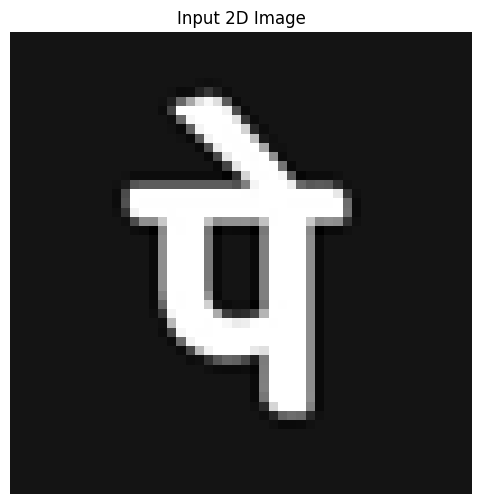

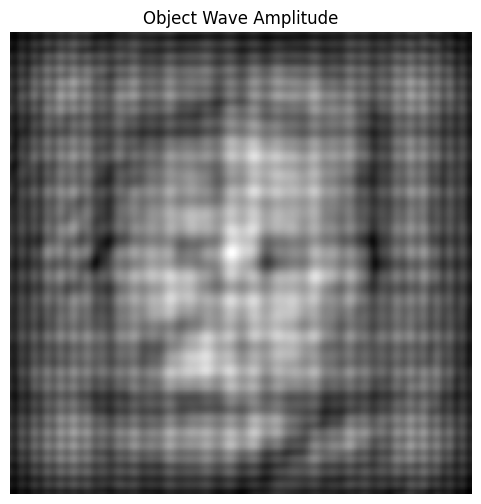

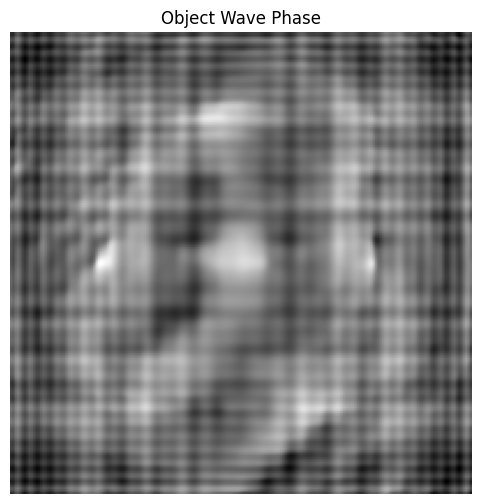

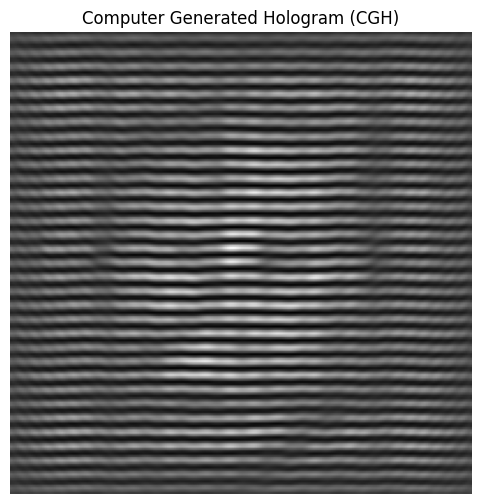

CGH generated successfully!
Saved at: output/cgh_hologram.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

image_path = "images.jpg"

img = Image.open(image_path).convert("L")


image_size = (50, 50)

img = img.resize(image_size)

image = np.array(img, dtype=np.float64)

intensity = image / 255.0

lambda_ = 532e-9          # wavelength = 532 nm
k = 2 * np.pi / lambda_   # wave number

hologram_width = 2e-3
hologram_height = 2e-3

Delta = 10e-6

hologram_z = 0

samplesX = int(hologram_width / Delta)
samplesY = int(hologram_height / Delta)

cornerX = -hologram_width / 2
cornerY = -hologram_height / 2

print("Hologram samples:", samplesX, "x", samplesY)


image_height, image_width = amplitude.shape

object_z = -0.2
object_width = 2e-3
object_height = 2e-3

points = []

for row in range(image_height):

    for column in range(image_width):

        A = amplitude[row, column]
        if A > 0:
            x = (
                (column / (image_width - 1))
                - 0.5
            ) * object_width
            y = (
                0.5 -
                (row / (image_height - 1))
            ) * object_height

            points.append([x, y, object_z, A])


points = np.array(points)

print("Number of object points:", len(points))

x_h = np.arange(samplesX) * Delta + cornerX
y_h = np.arange(samplesY) * Delta + cornerY

X, Y = np.meshgrid(x_h, y_h)

object_wave = np.zeros((samplesY, samplesX), dtype=np.complex128)

for s in range(len(points)):

    point_x = points[s, 0]
    point_y = points[s, 1]
    point_z = points[s, 2]
    point_amplitude = points[s, 3]


    r = np.sqrt(
        (X - point_x)**2 +
        (Y - point_y)**2 +
        (hologram_z - point_z)**2
    )
    object_wave += (
        point_amplitude *
        np.exp(1j * k * r) /
        r
    )
alpha = 90 * np.pi / 180
beta = 90.5 * np.pi / 180

nX = np.cos(alpha)
nY = np.cos(beta)

nZ = np.sqrt(
    1 - nX**2 - nY**2
)

refAmplitude = np.max(np.abs(object_wave))

reference_wave = (
    refAmplitude *
    np.exp(
        1j * k *
        (
            X * nX +
            Y * nY +
            hologram_z * nZ
        )
    )
)

optical_field = object_wave + reference_wave
hologram = np.real(
    optical_field *
    np.conj(optical_field)
)


hologram_display = (
    hologram - hologram.min()
) / (
    hologram.max() - hologram.min()
)
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Input 2D Image")
plt.axis("off")
plt.show()


plt.figure(figsize=(6, 6))
plt.imshow(
    np.abs(object_wave),
    cmap="gray"
)
plt.title("Object Wave Amplitude")
plt.axis("off")
plt.show()


plt.figure(figsize=(6, 6))
plt.imshow(
    np.angle(object_wave),
    cmap="gray"
)
plt.title("Object Wave Phase")
plt.axis("off")
plt.show()


plt.figure(figsize=(6, 6))
plt.imshow(
    hologram_display,
    cmap="gray"
)
plt.title("Computer Generated Hologram (CGH)")
plt.axis("off")
plt.show()


os.makedirs("output", exist_ok=True)

Image.fromarray(
    (hologram_display * 255).astype(np.uint8)
).save(
    "output/cgh_hologram.png"
)

Image.fromarray(
    (intensity * 255).astype(np.uint8)
).save(
    "output/input_intensity.png"
)

print("CGH generated successfully!")
print("Saved at: output/cgh_hologram.png")